# 04 · Modelo Preditivo: antecipando o NPS antes da pesquisa

**Pergunta que o modelo responde:**
> *"Com o que já sabemos sobre este pedido hoje (entrega, atraso, contatos, reclamações), qual nota esse cliente tende a dar — e ele precisa de uma ação agora?"*

## Estratégia adotada (e por quê)

| Decisão | Escolha | Justificativa técnica | Justificativa de negócio |
|---|---|---|---|
| **Tipo de problema** | **Regressão** da nota (0-10) como modelo principal; a nota prevista é convertida em **faixas de risco** e em Detrator/não detrator | A nota contínua preserva mais informação que uma classe (6,9 e 0,5 são "detratores" muito diferentes); um único modelo gera nota, categoria e ranking | Permite **priorizar** (quem está pior primeiro) e falar a língua do NPS. Uma classificação binária é treinada como **comparação** |
| **Variáveis de entrada** | Apenas dados disponíveis **antes** da pesquisa (cliente, pedido, logística, atendimento) | Evita *data leakage* | O modelo precisa funcionar no momento em que a ação ainda é possível |
| **Variáveis excluídas** | `csat_internal_score`, `repeat_purchase_30d`, IDs | São medidas de resultado coletadas junto/depois do NPS; IDs não têm significado | Um modelo que usa a recompra futura para prever a nota é inútil na operação |
| **Separação dos dados** | Treino 80% / teste 20%, estratificado pela categoria NPS + validação cruzada de 5 dobras no treino | Teste "guardado" mede desempenho em dados nunca vistos; estratificação mantém a proporção de promotores (só 4%) | Estimativa honesta de como o modelo vai performar em pedidos novos |
| **Modelo escolhido** | Comparação entre baseline, Regressão Linear, Random Forest e Gradient Boosting; escolha pela **simplicidade quando o desempenho empata** | Menos risco de *overfitting*, treino instantâneo, fácil de monitorar | **Explicável**: "cada dia de atraso tira ~1 ponto" é uma frase que um gestor entende e confia |
| **Avaliação** | MAE e R² (regressão); AUC, precisão e *recall* de detratores (classificação); acerto por faixa de risco | Métricas complementares | MAE = "erro médio em pontos de nota"; *recall* = "de cada 100 detratores, quantos o modelo avisa antes" |

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import joblib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    classification_report, confusion_matrix, mean_absolute_error, r2_score, roc_auc_score, root_mean_squared_error,
)
from sklearn.model_selection import KFold, cross_validate, train_test_split

from src.modeling import (
    MODEL_FEATURES, NUMERIC_FEATURES, RISK_BAND_ORDER, assign_risk_band, build_pipeline, score_orders,
)
from src.nps_utils import (
    DETRACTOR_THRESHOLD, FRIENDLY_NAMES, MODELS_DIR, POST_EXPERIENCE_FEATURES, RANDOM_STATE,
    classify_nps, load_processed_data, nps_index,
)
from src.viz import COLOR_ALERT, COLOR_MUTED, COLOR_NEUTRAL, COLOR_PRIMARY, COLOR_TEXT_SECONDARY, label_bars, save_figure, set_style

set_style()
df = load_processed_data()
print("Variáveis de entrada do modelo:", len(MODEL_FEATURES))
print(MODEL_FEATURES)

Variáveis de entrada do modelo: 14
['customer_age', 'customer_tenure_months', 'order_value', 'items_quantity', 'discount_value', 'payment_installments', 'delivery_time_days', 'delivery_delay_days', 'freight_value', 'delivery_attempts', 'customer_service_contacts', 'resolution_time_days', 'complaints_count', 'customer_region']


## 1. Definição da variável alvo

- **Alvo principal (regressão):** `nps_score`, nota de 0 a 10;
- **Alvo de comparação (classificação):** `is_detractor` = 1 se nota < 7.

Note que, nesta base, **84% dos clientes são detratores**. Isso muda a leitura das métricas de classificação: um modelo que chuta "todo mundo é detrator" acerta 84% — por isso a **acurácia sozinha engana** e usamos AUC e *recall*/precisão.

## 2. Separação treino/teste

In [2]:
X = df[MODEL_FEATURES]
y_score = df["nps_score"]
y_detractor = df["is_detractor"]

# Estratifica pela categoria NPS para manter a proporção de detratores/neutros/promotores nos dois conjuntos
X_train, X_test, y_train, y_test, yd_train, yd_test = train_test_split(
    X, y_score, y_detractor, test_size=0.2, random_state=RANDOM_STATE, stratify=df["nps_category"],
)
print(f"Treino: {len(X_train)} pedidos | Teste: {len(X_test)} pedidos")
pd.DataFrame({
    "treino (%)": classify_nps(y_train).value_counts(normalize=True).mul(100).round(1),
    "teste (%)": classify_nps(y_test).value_counts(normalize=True).mul(100).round(1),
})

Treino: 2000 pedidos | Teste: 500 pedidos


,treino (%),teste (%)
Detrator,84.4,84.4
Neutro,11.2,11.2
Promotor,4.4,4.4


> **Sobre a separação:** a base não tem data do pedido, então a separação é aleatória. Em produção, o correto seria uma **separação temporal** (treinar com meses passados e testar no mês seguinte), simulando o uso real e capturando mudanças de comportamento ao longo do tempo.

## 3. Comparação de modelos de regressão (validação cruzada no treino)

In [3]:
candidate_models = {
    "Baseline (média)": (DummyRegressor(strategy="mean"), True),
    "Regressão Linear": (LinearRegression(), True),
    "Random Forest": (RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=RANDOM_STATE, n_jobs=-1), False),
    "Gradient Boosting": (HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=300, random_state=RANDOM_STATE), False),
}
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_results = []
for name, (model, scale) in candidate_models.items():
    scores = cross_validate(build_pipeline(model, scale), X_train, y_train, cv=cv,
                            scoring={"mae": "neg_mean_absolute_error", "r2": "r2"})
    cv_results.append({
        "modelo": name,
        "MAE (pontos)": -scores["test_mae"].mean(),
        "MAE desvio": scores["test_mae"].std(),
        "R²": scores["test_r2"].mean(),
        "R² desvio": scores["test_r2"].std(),
    })
cv_table = pd.DataFrame(cv_results).set_index("modelo").round(3)
cv_table

,MAE (pontos),MAE desvio,R²,R² desvio
modelo,,,,
Baseline (média),2.039,0.026,-0.001,0.000
Regressão Linear,1.309,0.031,0.565,0.016
Random Forest,1.355,0.024,0.540,0.005
Gradient Boosting,1.340,0.014,0.543,0.009


**Leitura:**

- O **baseline** (chutar sempre a nota média) erra, em média, ~2,0 pontos;
- Os três modelos reduzem esse erro para ~1,3 ponto e explicam **~55% da variação** da nota usando só dados operacionais;
- **Regressão Linear, Random Forest e Gradient Boosting ficam praticamente empatados** (diferenças dentro do desvio da validação cruzada). Os modelos de árvore, mais complexos, não encontram padrões adicionais — sinal de que a relação entre operação e nota é essencialmente **aditiva e linear** (o que a EDA já sugeria: cada dia de atraso tira aproximadamente o mesmo tanto da nota).

**Escolha: Regressão Linear.** Com desempenho equivalente, ela vence em **explicabilidade, estabilidade e facilidade de manutenção** — e em um projeto cujo objetivo é orientar decisões, poder dizer *quanto* cada fator pesa vale mais que um ganho marginal de precisão.

> Os ~45% de variação não explicados representam o que **não está na base**: expectativa individual, qualidade do produto, comunicação, contexto do cliente. Isso é esperado em dados de satisfação e reforça que o modelo é um **sinal de alerta**, não uma bola de cristal.

## 4. O teste do vazamento de informação

Para mostrar por que excluímos `csat_internal_score` e `repeat_purchase_30d`, treinamos o mesmo modelo **com** elas:

In [4]:
leakage_features = MODEL_FEATURES + POST_EXPERIENCE_FEATURES
X_train_leak = df.loc[X_train.index, leakage_features]
leak_pipeline = build_pipeline(LinearRegression(), numeric_features=NUMERIC_FEATURES + POST_EXPERIENCE_FEATURES)
leak_scores = cross_validate(leak_pipeline, X_train_leak, y_train, cv=cv, scoring={"mae": "neg_mean_absolute_error", "r2": "r2"})
pd.DataFrame({
    "Sem vazamento (só pré-pesquisa)": [cv_table.loc["Regressão Linear", "MAE (pontos)"], cv_table.loc["Regressão Linear", "R²"]],
    "Com CSAT + recompra (vazamento)": [-leak_scores["test_mae"].mean(), leak_scores["test_r2"].mean()],
}, index=["MAE (pontos)", "R²"]).round(3)

,Sem vazamento (só pré-pesquisa),Com CSAT + recompra (vazamento)
MAE (pontos),1.309,1.183
R²,0.565,0.649


O modelo "com vazamento" parece melhor (R² sobe de ~0,57 para ~0,65), mas **é uma ilusão**: na hora em que precisamos da previsão, a recompra em 30 dias ainda não aconteceu e o CSAT ainda não foi respondido. Publicar esse número levaria a empresa a confiar em um desempenho que nunca se repetiria na prática.

## 5. Treino final e avaliação no conjunto de teste

In [5]:
final_pipeline = build_pipeline(LinearRegression())
final_pipeline.fit(X_train, y_train)

test_scored = score_orders(final_pipeline, df.loc[X_test.index])
predicted_test = test_scored["predicted_nps"]

baseline_mae = mean_absolute_error(y_test, np.full(len(y_test), y_train.mean()))
print(f"MAE  (erro médio)          : {mean_absolute_error(y_test, predicted_test):.2f} pontos  (baseline: {baseline_mae:.2f})")
print(f"RMSE                       : {root_mean_squared_error(y_test, predicted_test):.2f} pontos")
print(f"R²   (variação explicada)  : {r2_score(y_test, predicted_test):.2f}")
print(f"\nNPS real do conjunto de teste    : {nps_index(y_test):.1f}")
print(f"NPS previsto pelo modelo         : {nps_index(predicted_test):.1f}")
print(f"Nota média real vs prevista      : {y_test.mean():.2f} vs {predicted_test.mean():.2f}")

MAE  (erro médio)          : 1.39 pontos  (baseline: 2.11)
RMSE                       : 1.78 pontos
R²   (variação explicada)  : 0.51

NPS real do conjunto de teste    : -80.0
NPS previsto pelo modelo         : -92.0
Nota média real vs prevista      : 4.24 vs 4.46


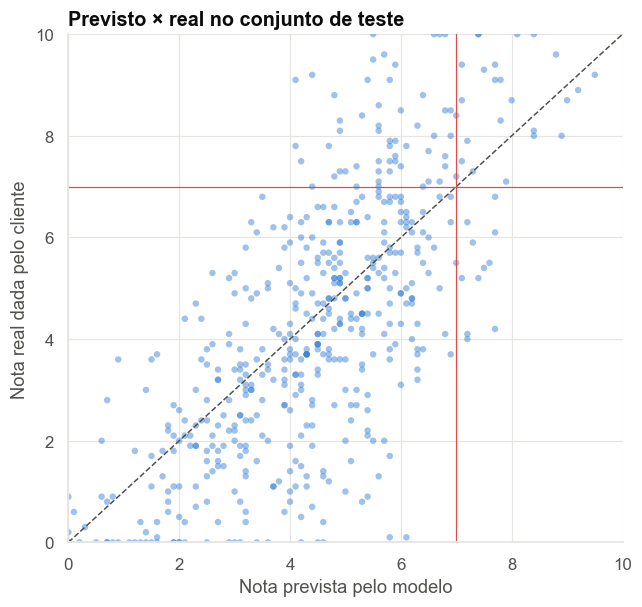

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(predicted_test, y_test, s=18, alpha=0.45, color=COLOR_PRIMARY, edgecolor="none")
ax.plot([0, 10], [0, 10], color=COLOR_TEXT_SECONDARY, linestyle="--", linewidth=1)
ax.axhline(DETRACTOR_THRESHOLD, color=COLOR_ALERT, linewidth=0.8)
ax.axvline(DETRACTOR_THRESHOLD, color=COLOR_ALERT, linewidth=0.8)
ax.set_xlim(0, 10); ax.set_ylim(0, 10)
ax.set_xlabel("Nota prevista pelo modelo")
ax.set_ylabel("Nota real dada pelo cliente")
ax.set_title("Previsto × real no conjunto de teste")
ax.grid(axis="x")
save_figure(fig, "11_previsto_vs_real.png")
plt.show()

No teste (500 pedidos nunca vistos), o modelo erra em média **1,4 ponto** (contra 2,1 do baseline) e explica **~51%** da variação — em linha com a validação cruzada, ou seja, sem sinais de *overfitting*. Ele acompanha bem a tendência, mas é "conservador" nos extremos: dificilmente prevê notas acima de 8,5, porque nada nos dados operacionais distingue um cliente "satisfeito" (8) de um "encantado" (10) — essa diferença depende de fatores fora da base. Por isso, para estimar o NPS agregado, o melhor uso é a **nota média prevista e as faixas de risco**, e não a contagem de "promotores previstos" (o NPS calculado diretamente sobre a nota prevista sai mais negativo que o real).

## 6. Avaliação na linguagem do negócio: faixas de risco

Na prática, a operação não precisa da nota exata — precisa saber **em quem agir primeiro**. Convertemos a nota prevista em três faixas:

| Faixa | Nota prevista | Ação sugerida |
|---|---|---|
| **Risco alto** | < 4 | Ação imediata e personalizada (contato ativo, solução prioritária, compensação) |
| **Risco moderado** | 4 a < 7 | Ação preventiva automatizada (aviso proativo, acompanhamento do caso) |
| **Risco baixo** | ≥ 7 | Fluxo padrão; candidato a programa de indicação |

In [7]:
risk_table = (
    test_scored.assign(real_category=classify_nps(test_scored["nps_score"]))
    .groupby("risk_band", observed=False)
    .agg(pedidos=("nps_score", "size"),
         nota_real_media=("nps_score", "mean"),
         pct_detratores_reais=("is_detractor", lambda s: 100 * s.mean()),
         pct_promotores_reais=("nps_score", lambda s: 100 * (s >= 9).mean()))
    .round(1)
)
risk_table["% dos pedidos"] = (100 * risk_table["pedidos"] / risk_table["pedidos"].sum()).round(1)
risk_table

,pedidos,nota_real_media,pct_detratores_reais,pct_promotores_reais,% dos pedidos
risk_band,,,,,
Risco alto,175,2.2,100.0,0.0,35.0
Risco moderado,288,5.0,81.6,3.8,57.6
Risco baixo,37,7.6,32.4,29.7,7.4


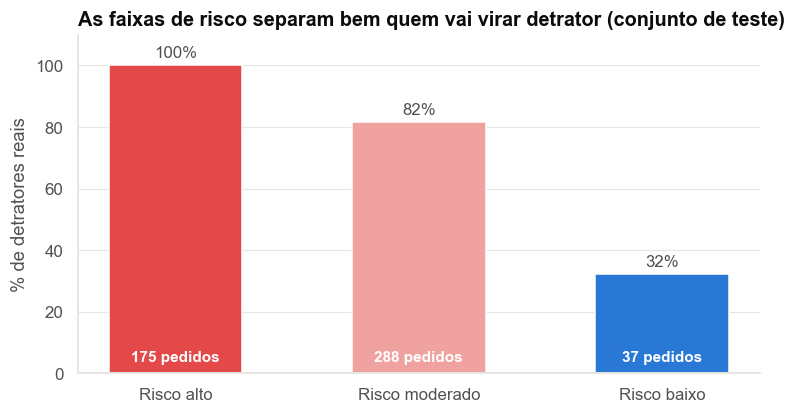

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(risk_table.index.astype(str), risk_table["pct_detratores_reais"], color=[COLOR_ALERT, "#f0a2a1", COLOR_PRIMARY], width=0.55)
label_bars(ax, fmt="{:.0f}", suffix="%", fontsize=11)
for x, n in enumerate(risk_table["pedidos"]):
    ax.text(x, 4, f"{n} pedidos", ha="center", color="white", fontsize=10, fontweight="bold")
ax.set_ylim(0, 110)
ax.set_ylabel("% de detratores reais")
ax.set_title("As faixas de risco separam bem quem vai virar detrator (conjunto de teste)")
save_figure(fig, "12_faixas_de_risco.png")
plt.show()

As faixas funcionam como esperado: na faixa de **risco alto** praticamente todos os clientes viraram de fato detratores; na faixa de **risco baixo**, a proporção cai drasticamente e aparecem os promotores. Isso dá à operação uma **fila priorizada** confiável.

## 7. Comparação: modelo de classificação (detrator × não detrator)

In [9]:
# Regressão logística com pesos balanceados: como só 16% NÃO são detratores, o balanceamento evita
# que o modelo simplesmente aprenda a dizer "detrator" para todo mundo.
classifier_pipeline = build_pipeline(LogisticRegression(max_iter=2000, class_weight="balanced"))
classifier_pipeline.fit(X_train, yd_train)
detractor_probability = classifier_pipeline.predict_proba(X_test)[:, 1]
detractor_prediction = (detractor_probability >= 0.5).astype(int)

majority_baseline = DummyClassifier(strategy="most_frequent").fit(X_train, yd_train)
print(f"Acurácia do baseline 'todo mundo é detrator': {(majority_baseline.predict(X_test) == yd_test).mean():.2f}  <- por isso acurácia engana")
print(f"AUC da classificação (logística)          : {roc_auc_score(yd_test, detractor_probability):.3f}")
print(f"AUC usando a nota prevista da regressão   : {roc_auc_score(yd_test, -predicted_test):.3f}")
print()
print(classification_report(yd_test, detractor_prediction, target_names=["Não detrator", "Detrator"], digits=2))

Acurácia do baseline 'todo mundo é detrator': 0.84  <- por isso acurácia engana
AUC da classificação (logística)          : 0.871
AUC usando a nota prevista da regressão   : 0.867

              precision    recall  f1-score   support

Não detrator       0.42      0.78      0.55        78
    Detrator       0.95      0.80      0.87       422

    accuracy                           0.80       500
   macro avg       0.69      0.79      0.71       500
weighted avg       0.87      0.80      0.82       500



In [10]:
matrix = pd.DataFrame(
    confusion_matrix(yd_test, detractor_prediction),
    index=["Real: não detrator", "Real: detrator"],
    columns=["Previsto: não detrator", "Previsto: detrator"],
)
matrix

,Previsto: não detrator,Previsto: detrator
Real: não detrator,61,17
Real: detrator,84,338


**Leitura:**

- A **AUC** (~0,87) indica que, sorteando um detrator e um não detrator, o modelo coloca o detrator como "mais arriscado" em quase 9 de cada 10 vezes;
- Com corte em 0,5, o modelo **avisa 80% dos detratores** (*recall*) e, quando aponta alguém como detrator, acerta 95% das vezes (precisão);
- A **regressão já entrega praticamente a mesma capacidade de separação** (AUC muito próxima) — confirmando que um único modelo de regressão atende os dois usos (nota + classificação), com a vantagem de manter a nuance da nota;
- O **ponto de corte** (aqui 0,5) é uma decisão de negócio: baixar o corte aumenta o *recall* (avisa mais detratores) ao custo de mais "alarmes falsos". Como agir preventivamente custa pouco (uma mensagem, um acompanhamento), vale priorizar *recall*.

## 8. O que o modelo aprendeu: quanto cada fator pesa

In [11]:
# Coeficientes em unidades originais: "quanto a nota muda com +1 unidade da variável"
# (o modelo foi treinado com variáveis padronizadas, então dividimos pelo desvio-padrão)
linear_model = final_pipeline.named_steps["model"]
feature_names = final_pipeline.named_steps["preprocess"].get_feature_names_out()
scaler = final_pipeline.named_steps["preprocess"].named_transformers_["numeric"]

coefficients = pd.Series(linear_model.coef_, index=feature_names)
original_unit_effect = coefficients[NUMERIC_FEATURES] / scaler.scale_
effects = pd.DataFrame({
    "fator": [FRIENDLY_NAMES[c] for c in NUMERIC_FEATURES],
    "efeito na nota por +1 unidade": original_unit_effect.values,
}).set_index("fator").sort_values("efeito na nota por +1 unidade")
effects.round(3)

,efeito na nota por +1 unidade
fator,
Atraso na entrega (dias),-0.937
Nº de reclamações,-0.374
Contatos com o SAC,-0.353
Tempo de resolução (dias),-0.140
Frete (R$),-0.007
Tempo de entrega (dias),-0.002
Desconto (R$),-0.001
Tempo de casa (meses),-0.001
Valor do pedido (R$),0.001


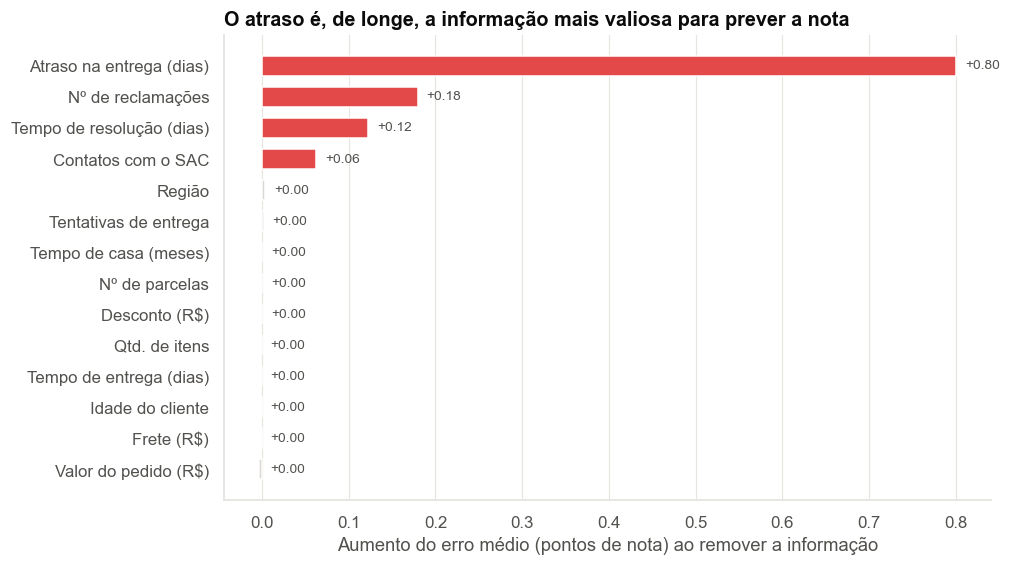

In [12]:
# Importância por permutação: quanto o erro do modelo piora se "embaralharmos" cada variável.
# É uma medida independente do tipo de modelo e fácil de explicar.
importance = permutation_importance(final_pipeline, X_test, y_test, n_repeats=30, random_state=RANDOM_STATE,
                                    scoring="neg_mean_absolute_error")
importance_table = pd.Series(importance.importances_mean, index=MODEL_FEATURES).sort_values()
importance_table.index = [FRIENDLY_NAMES[c] for c in importance_table.index]

fig, ax = plt.subplots(figsize=(9, 5.5))
colors = [COLOR_ALERT if v > 0.05 else COLOR_MUTED for v in importance_table.values]
ax.barh(importance_table.index, importance_table.values, color=colors, height=0.65)
for y, value in enumerate(importance_table.values):
    ax.text(max(value, 0) + 0.01, y, f"+{max(value, 0):.2f}", va="center", fontsize=9, color=COLOR_TEXT_SECONDARY)
ax.set_title("O atraso é, de longe, a informação mais valiosa para prever a nota")
ax.set_xlabel("Aumento do erro médio (pontos de nota) ao remover a informação")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
save_figure(fig, "13_importancia_modelo.png")
plt.show()

O modelo confirma a EDA com números diretos:

| Fator | Efeito estimado na nota |
|---|---|
| +1 dia de atraso | **≈ −1,0 ponto** |
| +1 reclamação | ≈ −0,4 ponto |
| +1 contato com o SAC | ≈ −0,35 ponto |
| +1 dia para resolver | ≈ −0,15 ponto |
| Frete, valor, desconto, parcelas, itens, tentativas, idade, tempo de casa, região | ≈ 0 (efeitos desprezíveis) |

## 9. Simulação: quanto o NPS melhoraria?

Usando os efeitos estimados, simulamos cenários de melhoria operacional sobre a base completa. A nota de cada cliente é ajustada pelo efeito da mudança (limitada entre 0 e 10) e o NPS é recalculado.

> **Cuidado:** é uma simulação baseada em associações observadas, não uma garantia causal — serve para **ordenar prioridades e dimensionar ganhos**, e deve ser validada com testes controlados (ver notebook / apresentação).

In [13]:
effect_per_unit = original_unit_effect  # efeitos por variável, em pontos de nota


def simulate_scenario(data: pd.DataFrame, changes: dict) -> float:
    # Aplica mudanças nas variáveis e devolve o NPS simulado (nota real + efeito estimado da mudança)
    simulated_score = data["nps_score"].copy()
    for column, new_values in changes.items():
        simulated_score += effect_per_unit[column] * (new_values - data[column])
    return nps_index(simulated_score.clip(0, 10))


scenarios = {
    "Situação atual": {},
    "Atraso máximo de 1 dia": {"delivery_delay_days": df["delivery_delay_days"].clip(upper=1)},
    "Reduzir 1 dia de atraso em todos os pedidos atrasados": {"delivery_delay_days": (df["delivery_delay_days"] - 1).clip(lower=0)},
    "Resolver com 1 contato (máx.)": {"customer_service_contacts": df["customer_service_contacts"].clip(upper=1)},
    "Resolução em até 2 dias": {"resolution_time_days": df["resolution_time_days"].clip(upper=2)},
    "Combinado: atraso ≤ 1 dia + 1 contato + resolução ≤ 2 dias": {
        "delivery_delay_days": df["delivery_delay_days"].clip(upper=1),
        "customer_service_contacts": df["customer_service_contacts"].clip(upper=1),
        "resolution_time_days": df["resolution_time_days"].clip(upper=2),
    },
}
scenario_table = pd.Series({name: simulate_scenario(df, changes) for name, changes in scenarios.items()}, name="NPS simulado").round(1).to_frame()
scenario_table["ganho vs atual (pontos)"] = (scenario_table["NPS simulado"] - scenario_table.loc["Situação atual", "NPS simulado"]).round(1)
scenario_table

,NPS simulado,ganho vs atual (pontos)
Situação atual,-80.0,0.0
Atraso máximo de 1 dia,-68.9,11.1
Reduzir 1 dia de atraso em todos os pedidos atrasados,-69.1,10.9
Resolver com 1 contato (máx.),-78.4,1.6
Resolução em até 2 dias,-73.4,6.6
Combinado: atraso ≤ 1 dia + 1 contato + resolução ≤ 2 dias,-54.8,25.2


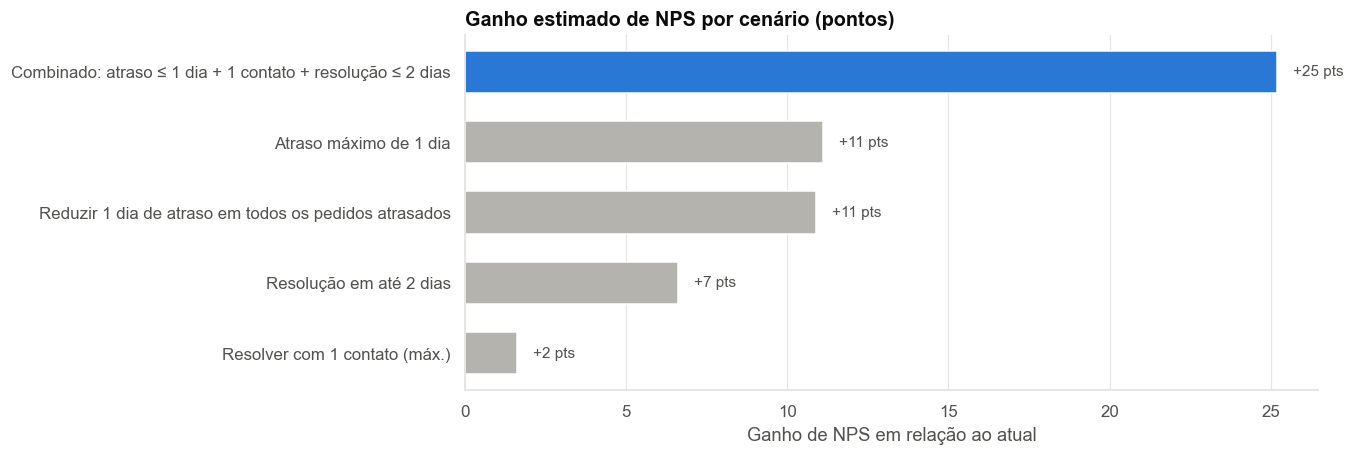

In [14]:
plot_table = scenario_table.drop("Situação atual").sort_values("ganho vs atual (pontos)")
fig, ax = plt.subplots(figsize=(10, 4.2))
colors = [COLOR_PRIMARY if "Combinado" in name else COLOR_NEUTRAL for name in plot_table.index]
ax.barh(plot_table.index, plot_table["ganho vs atual (pontos)"], color=colors, height=0.6)
for y, value in enumerate(plot_table["ganho vs atual (pontos)"]):
    ax.text(value + 0.5, y, f"+{value:.0f} pts", va="center", fontsize=10, color=COLOR_TEXT_SECONDARY)
ax.set_title("Ganho estimado de NPS por cenário (pontos)")
ax.set_xlabel("Ganho de NPS em relação ao atual")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
save_figure(fig, "14_simulacao_cenarios.png")
plt.show()

**Leitura:** atacar o **atraso** é, isoladamente, a alavanca de maior retorno; mas o ganho mais expressivo vem da **combinação** logística + atendimento. Mesmo no cenário combinado o NPS continua negativo — mostrando que **o problema é grande e exige um programa contínuo**, não uma ação pontual — mas o movimento é de dezenas de pontos.

## 10. Salvando o modelo e exemplo de uso

In [15]:
# Treina o modelo final com TODOS os dados (treino + teste) antes de salvar, para aproveitar toda a informação.
production_pipeline = build_pipeline(LinearRegression()).fit(X, y_score)
MODELS_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump(production_pipeline, MODELS_DIR / "nps_regressor.joblib")
print("Modelo salvo em models/nps_regressor.joblib")

# Exemplo: três pedidos "em andamento" (sem nota NPS) sendo pontuados
example_orders = pd.DataFrame([
    {"customer_age": 35, "customer_region": "Sudeste", "customer_tenure_months": 24, "order_value": 320.0, "items_quantity": 2,
     "discount_value": 20.0, "payment_installments": 3, "delivery_time_days": 7, "delivery_delay_days": 0, "freight_value": 30.0,
     "delivery_attempts": 1, "customer_service_contacts": 0, "resolution_time_days": 0, "complaints_count": 1},
    {"customer_age": 52, "customer_region": "Nordeste", "customer_tenure_months": 80, "order_value": 610.0, "items_quantity": 4,
     "discount_value": 35.0, "payment_installments": 6, "delivery_time_days": 9, "delivery_delay_days": 2, "freight_value": 45.0,
     "delivery_attempts": 2, "customer_service_contacts": 1, "resolution_time_days": 3, "complaints_count": 3},
    {"customer_age": 28, "customer_region": "Norte", "customer_tenure_months": 6, "order_value": 150.0, "items_quantity": 1,
     "discount_value": 5.0, "payment_installments": 1, "delivery_time_days": 12, "delivery_delay_days": 4, "freight_value": 50.0,
     "delivery_attempts": 3, "customer_service_contacts": 3, "resolution_time_days": 9, "complaints_count": 6},
], index=["Pedido A", "Pedido B", "Pedido C"])
score_orders(production_pipeline, example_orders)[["delivery_delay_days", "complaints_count", "customer_service_contacts", "predicted_nps", "risk_band"]]

Modelo salvo em models/nps_regressor.joblib


,delivery_delay_days,complaints_count,customer_service_contacts,predicted_nps,risk_band
Pedido A,0,1,0,8.9,Risco baixo
Pedido B,2,3,1,5.5,Risco moderado
Pedido C,4,6,3,0.8,Risco alto


## 11. Como a empresa usaria isso na prática

1. **Pontuação diária (ou a cada evento):** toda vez que um pedido muda de status (despachado, atrasou, cliente ligou, abriu reclamação), o modelo recalcula a nota prevista — `python -m src.predict` mostra a versão em lote;
2. **Fila priorizada:** pedidos em **risco alto** vão para uma fila do time de CX com ação humana; **risco moderado** dispara ações automáticas (mensagem proativa de status, novo prazo realista, canal prioritário);
3. **Gatilhos de negócio derivados do modelo** (simples e auditáveis): "pedido completou 1 dia de atraso" e "cliente abriu a 2ª reclamação" são os dois pontos de ruptura — devem disparar alertas mesmo antes de qualquer modelo;
4. **Painel de "NPS previsto":** acompanhar o NPS estimado da semana em tempo real, por região/transportadora/categoria, sem esperar a pesquisa;
5. **Medição de impacto com grupo de controle:** aplicar as ações em parte dos clientes em risco e comparar com um grupo semelhante sem ação (teste A/B), para provar o efeito causal e calcular o retorno;
6. **Monitoramento e re-treino:** comparar mensalmente nota prevista × nota real; se o erro subir (mudança de comportamento, nova transportadora), re-treinar.

## 12. Limitações do modelo

- Explica ~55% da variação: **é um sinal de alerta, não uma sentença** — o cliente sempre pode surpreender;
- Aprende **associações**, não causas; os efeitos estimados devem ser validados com testes controlados;
- A base não tem tempo (datas), canal, produto, transportadora nem texto das reclamações — informações que provavelmente melhorariam o modelo;
- Variáveis como `complaints_count` e `resolution_time_days` só ficam completas ao final do atendimento; em produção o modelo deve usar o **valor acumulado até o momento** da previsão;
- Notas acima de ~8,5 são pouco previsíveis: o modelo é bom em detectar **risco**, não em identificar **encantamento**;
- Possível viés de resposta da pesquisa (só quem respondeu está na base).